# Module 05, Part 3: Positional encodings

This notebook is the runnable companion to Part 3 of the Module 05 learning
content. It checks, with code:

1. Attention has no sense of order. Shuffle the input and the output is shuffled
   the same way; nothing else changes.
2. A task that depends only on order is at chance without positional information
   and solved with it, using learned or sinusoidal encodings.
3. Sinusoidal encodings have a property that makes them attractive: the
   similarity of two positions depends only on how far apart they are.
4. A limit worth knowing. Being *defined* at a longer length does not mean a
   trained model *works* at that length.

Everything runs on CPU in a few minutes.

In [1]:
import math
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

torch.manual_seed(0)
print("PyTorch version:", torch.__version__)

def causal_mask(length):
    """Boolean mask of shape (length, length). True means 'this position may be attended to'.
    Row i (the query) may look at columns 0..i (the keys), never at the future."""
    return torch.tril(torch.ones(length, length, dtype=torch.bool))


def scaled_dot_product_attention(q, k, v, mask=None, scale=True):
    """softmax(q k^T / sqrt(d_k)) v.

    q: (..., T_q, d_k)   k: (..., T_k, d_k)   v: (..., T_k, d_v)
    mask: boolean, broadcastable to (..., T_q, T_k); False entries are blocked.
    Returns (output, weights). Set scale=False to see why the scaling matters.
    """
    d_k = q.shape[-1]
    scores = q @ k.transpose(-2, -1)
    if scale:
        scores = scores / math.sqrt(d_k)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    weights = torch.softmax(scores, dim=-1)
    return weights @ v, weights


class MultiHeadAttention(nn.Module):
    """Several attention heads that run side by side on lower-dimensional projections.

    d_model is split into n_heads slices of size d_model // n_heads. Each head has
    its own query, key and value projection (stored together in one weight matrix
    each), attends on its own, and the head outputs are concatenated and mixed by
    a final linear layer.
    """

    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.d_model, self.n_heads, self.d_head = d_model, n_heads, d_model // n_heads
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)

    def split_heads(self, x):
        batch, length, _ = x.shape
        return x.view(batch, length, self.n_heads, self.d_head).transpose(1, 2)  # (batch, heads, T, d_head)

    def forward(self, x, context=None, mask=None, head_mask=None, return_weights=False):
        """x supplies the queries. context supplies keys and values (cross-attention);
        by default it is x itself (self-attention). head_mask is an optional tensor of
        shape (n_heads,) of 0/1 values used to switch individual heads off."""
        context = x if context is None else context
        q = self.split_heads(self.w_q(x))
        k = self.split_heads(self.w_k(context))
        v = self.split_heads(self.w_v(context))
        out, weights = scaled_dot_product_attention(q, k, v, mask=mask)
        if head_mask is not None:
            out = out * head_mask.view(1, -1, 1, 1)
        batch, _, length, _ = out.shape
        out = out.transpose(1, 2).reshape(batch, length, self.d_model)  # concatenate the heads
        out = self.w_o(out)
        return (out, weights) if return_weights else out

PyTorch version: 2.10.0+cpu


## 1. Attention cannot tell the order of its inputs

Attention compares every pair of positions by content. No step of the computation
uses the index of a position, so shuffling the inputs can only shuffle the
outputs. We check it: apply a random permutation to the inputs, and compare with
applying the same permutation to the outputs.

In [2]:
torch.manual_seed(0)
mha = MultiHeadAttention(32, 4)
x = torch.randn(2, 8, 32)
perm = torch.randperm(8)

out = mha(x)
out_of_shuffled = mha(x[:, perm])
print("permutation of the input permutes the output:", torch.allclose(out[:, perm], out_of_shuffled, atol=1e-5))
print("the output for the original order and the shuffled order are different tensors:",
      not torch.allclose(out, out_of_shuffled, atol=1e-5))

permutation of the input permutes the output: True
the output for the original order and the shuffled order are different tensors: True


A recurrent network gets order for free, because it reads one step after
another. Attention gets none, so a Transformer must be **given** the position,
by adding a position-dependent vector to every input before the first layer.

## 2. A task that only order can solve

Every sequence contains the marker token 1 exactly once and the marker token 2
exactly once, plus random filler tokens. The label is 1 if marker 1 comes first
and 0 if marker 2 comes first. The two classes contain **exactly the same
tokens**, so only the order separates them. Chance is 0.5.

In [3]:
def make_order_batch(batch_size, seq_len, generator, vocab=10):
    """Order task. Every sequence contains the marker tokens 1 and 2 exactly once, the rest is
    random filler from 3..vocab-1. The label is 1 if marker 1 comes before marker 2, else 0.
    The two classes contain exactly the same tokens, so only the order separates them."""
    tokens = torch.randint(3, vocab, (batch_size, seq_len), generator=generator)
    pos = torch.stack([torch.randperm(seq_len, generator=generator)[:2] for _ in range(batch_size)])
    rows = torch.arange(batch_size)
    tokens[rows, pos[:, 0]] = 1
    tokens[rows, pos[:, 1]] = 2
    labels = (pos[:, 0] < pos[:, 1]).long()
    return tokens, labels

In [4]:
x, y = make_order_batch(6, 12, torch.Generator().manual_seed(2))
for row, label in zip(x.tolist(), y.tolist()):
    print(row, " ->", "1 before 2" if label else "2 before 1")

[5, 6, 7, 2, 7, 3, 9, 8, 1, 7, 5, 6]  -> 2 before 1
[9, 7, 8, 4, 1, 6, 7, 4, 6, 2, 4, 6]  -> 1 before 2
[8, 7, 3, 4, 6, 3, 2, 6, 1, 7, 4, 8]  -> 2 before 1
[1, 7, 5, 6, 3, 2, 5, 4, 4, 4, 6, 9]  -> 1 before 2
[6, 2, 1, 3, 8, 3, 9, 9, 6, 4, 5, 8]  -> 2 before 1
[1, 3, 6, 9, 3, 5, 9, 5, 8, 5, 2, 9]  -> 1 before 2


## 3. Two ways to provide position

**Learned**: a table with one trainable vector per position, up to a fixed
maximum length. **Sinusoidal**: a fixed formula, with no parameters. For position
$p$ and dimension pair $i$:

$$PE_{(p,\,2i)} = \sin\!\left(\frac{p}{10000^{2i/d}}\right), \qquad PE_{(p,\,2i+1)} = \cos\!\left(\frac{p}{10000^{2i/d}}\right)$$

Low dimensions oscillate fast and high dimensions slowly, like the digits of a
counter.

In [5]:
def sinusoidal_encoding(max_len, d_model):
    """Fixed encoding. Pair (2i, 2i+1) of position p holds sin and cos of p / 10000^(2i/d_model).
    Returns a tensor of shape (max_len, d_model). Needs no training and is defined for any length."""
    position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
    freq = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
    pe = torch.zeros(max_len, d_model)
    pe[:, 0::2] = torch.sin(position * freq)
    pe[:, 1::2] = torch.cos(position * freq)
    return pe


class LearnedPositions(nn.Module):
    """One trainable vector per position, up to max_len. Positions beyond max_len do not exist."""

    def __init__(self, max_len, d_model):
        super().__init__()
        self.table = nn.Embedding(max_len, d_model)

    def forward(self, length):
        return self.table(torch.arange(length, device=self.table.weight.device))

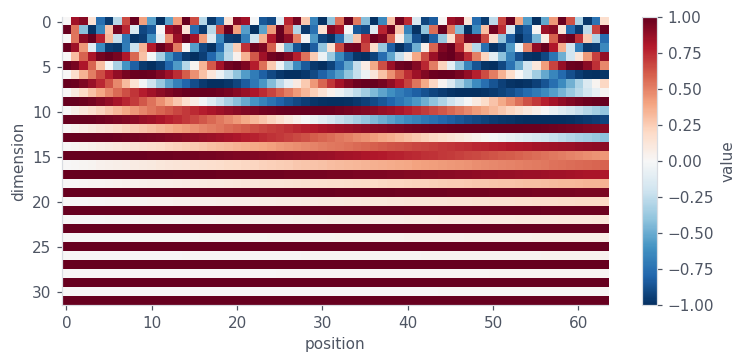

In [6]:
pe = sinusoidal_encoding(64, 32)
fig, ax = plt.subplots(figsize=(7, 3.4))
im = ax.imshow(pe.T, cmap="RdBu_r", aspect="auto", vmin=-1, vmax=1)
ax.set_xlabel("position"); ax.set_ylabel("dimension"); ax.grid(False)
plt.colorbar(im, ax=ax, label="value"); plt.tight_layout(); plt.show()

### What the sinusoidal encoding guarantees

For any fixed offset $k$, $PE_{p+k}$ is a **linear function** of $PE_p$ (each sine,
cosine pair is rotated by an angle that depends only on $k$). So a model can learn
to attend to "the token $k$ steps back" with one fixed set of weights, whatever
the position. And the dot product between two encodings depends only on the gap
between the positions. We check both.

largest error when one fixed matrix predicts PE(p+5) from PE(p), over 150 positions: 2.9e-06
dot product of PE(p) and PE(p+gap), spread over every p:
  gap  0: mean  16.000   std across p 1.5e-07
  gap  6: mean  11.892   std across p 1.7e-06
  gap 12: mean  11.449   std across p 1.2e-06
  gap 18: mean   9.797   std across p 2.1e-06
  gap 24: mean   9.929   std across p 1.8e-06


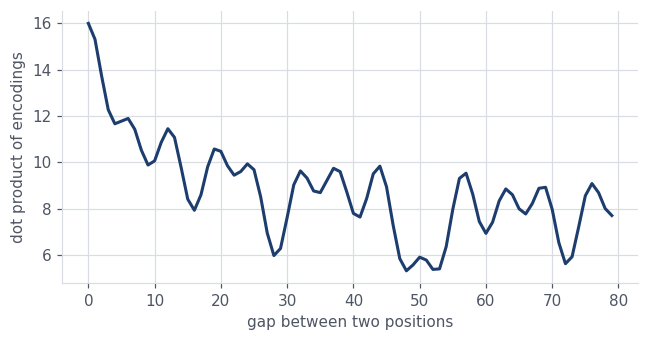

In [7]:
pe = sinusoidal_encoding(200, 32).double()
k = 5
P, Q = pe[:150], pe[k:150 + k]                            # PE_p and PE_{p+k}, for 150 values of p
M = torch.linalg.lstsq(P, Q).solution                      # one matrix mapping every PE_p to PE_{p+k}
print(f"largest error when one fixed matrix predicts PE(p+{k}) from PE(p), over 150 positions: {(P @ M - Q).abs().max():.1e}")

gram = pe @ pe.T
gaps = list(range(0, 60, 6))
print("dot product of PE(p) and PE(p+gap), spread over every p:")
for gap in gaps[:5]:
    vals = torch.diagonal(gram, offset=gap)
    print(f"  gap {gap:2d}: mean {vals.mean():7.3f}   std across p {vals.std():.1e}")

plt.figure(figsize=(6, 3.2))
plt.plot(range(80), [torch.diagonal(gram, offset=g).mean().item() for g in range(80)], color=NAVY, lw=2)
plt.xlabel("gap between two positions"); plt.ylabel("dot product of encodings")
plt.tight_layout(); plt.show()

Both properties hold to within float32 rounding: the fixed matrix predicts
$PE_{p+5}$ with an error of about $10^{-6}$, and the dot product for a given gap
varies across $p$ by about $10^{-6}$. The dot product falls, with some ripple, as the gap
grows, so nearby positions look more alike than distant ones, with no training.

## 4. Training the order task three ways

A small encoder (2 blocks, 4 heads, width 32), mean pooling, trained for 800
updates on sequences of length 16, same optimizer and clipping throughout. We test
at length 16 (the training length) and at length 32 (twice as long). Three seeds
each; we report every seed.

In [8]:
class FeedForward(nn.Module):
    """The position-wise network: two linear layers with a nonlinearity between them,
    applied to every position independently."""

    def __init__(self, d_model, d_ff):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    """One encoder block: self-attention, then a feed-forward network, each wrapped in a residual path.

    norm='pre'  : x = x + sublayer(LayerNorm(x))   (normalize on the branch, residual path stays clean)
    norm='post' : x = LayerNorm(x + sublayer(x))   (normalize after the addition, as in the original design)
    causal=True blocks attention to future positions, which turns the block into a decoder-style block.
    """

    def __init__(self, d_model, n_heads, d_ff, norm="pre", causal=False):
        super().__init__()
        assert norm in ("pre", "post")
        self.norm_type, self.causal = norm, causal
        self.attn = MultiHeadAttention(d_model, n_heads)
        self.ff = FeedForward(d_model, d_ff)
        self.ln1, self.ln2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)

    def forward(self, x, head_mask=None, return_weights=False):
        mask = causal_mask(x.shape[1]).to(x.device) if self.causal else None
        weights = None
        if self.norm_type == "pre":
            a = self.attn(self.ln1(x), mask=mask, head_mask=head_mask, return_weights=return_weights)
            a, weights = a if return_weights else (a, None)
            x = x + a
            x = x + self.ff(self.ln2(x))
        else:
            a = self.attn(x, mask=mask, head_mask=head_mask, return_weights=return_weights)
            a, weights = a if return_weights else (a, None)
            x = self.ln1(x + a)
            x = self.ln2(x + self.ff(x))
        return (x, weights) if return_weights else x


class SequenceClassifier(nn.Module):
    """Token embedding, optional positional encoding, a stack of encoder blocks, mean pooling, a linear head.

    pos: 'none', 'learned' or 'sinusoidal'. For 'learned', max_len fixes how many positions exist.
    inputs: integer token ids of shape (batch, T).
    """

    def __init__(self, vocab, n_classes, d_model=32, n_heads=4, d_ff=64, n_layers=2,
                 pos="sinusoidal", max_len=64, norm="pre"):
        super().__init__()
        self.pos_kind, self.d_model = pos, d_model
        self.embed = nn.Embedding(vocab, d_model)
        if pos == "learned":
            self.pos = LearnedPositions(max_len, d_model)
        elif pos == "sinusoidal":
            self.register_buffer("pe", sinusoidal_encoding(max_len, d_model))
        self.blocks = nn.ModuleList([TransformerBlock(d_model, n_heads, d_ff, norm=norm) for _ in range(n_layers)])
        self.final_norm = nn.LayerNorm(d_model) if norm == "pre" else nn.Identity()
        self.head = nn.Linear(d_model, n_classes)

    def encode(self, tokens, head_mask=None):
        x = self.embed(tokens)
        length = tokens.shape[1]
        if self.pos_kind == "learned":
            x = x + self.pos(length)
        elif self.pos_kind == "sinusoidal":
            x = x + self.pe[:length]
        for block in self.blocks:
            x = block(x, head_mask=head_mask)
        return self.final_norm(x)

    def forward(self, tokens, head_mask=None):
        return self.head(self.encode(tokens, head_mask).mean(dim=1))

In [9]:
def train_order(pos, seed, T=16, steps=800, test_lengths=(16, 32)):
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed + 100)
    model = SequenceClassifier(vocab=10, n_classes=2, pos=pos, max_len=64)
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    for _ in range(steps):
        x, y = make_order_batch(64, T, gen)
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
    accs = []
    with torch.no_grad():
        for L in test_lengths:
            xv, yv = make_order_batch(1000, L, torch.Generator().manual_seed(999))
            accs.append((model(xv).argmax(1) == yv).float().mean().item())
    return accs

order_results = {}
print(f"{'positions':>11s}   accuracy at length 16 / length 32, for seeds 0, 1, 2")
for pos in ("none", "learned", "sinusoidal"):
    order_results[pos] = [train_order(pos, s) for s in range(3)]
    print(f"{pos:>11s}   " + "   ".join(f"{a:.2f} / {b:.2f}" for a, b in order_results[pos]))

  positions   accuracy at length 16 / length 32, for seeds 0, 1, 2
       none   0.55 / 0.50   0.52 / 0.48   0.45 / 0.50
    learned   1.00 / 0.62   1.00 / 0.59   1.00 / 0.65
 sinusoidal   1.00 / 0.62   1.00 / 0.67   1.00 / 0.75


Without any positional information the model sits at chance (0.5), as section 1
predicted. With either kind of position it solves the task at the training length.

### The part that does not work

At length 32, both models fall well short of 1.0. The sinusoidal encoding **exists**
at positions 16 to 31, but the model never saw those positions during training and
did not learn a rule that carries over. The learned table is worse in principle:
rows 16 to 31 were never trained at all.

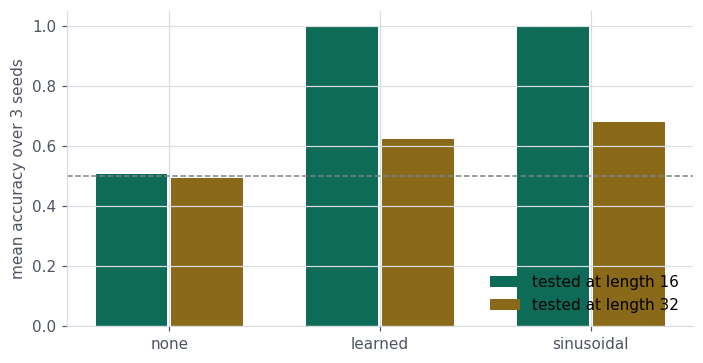

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
labels = ["none", "learned", "sinusoidal"]
for j, (L, color) in enumerate(zip((16, 32), (GREEN, AMBER))):
    means = [sum(r[j] for r in order_results[p]) / 3 for p in labels]
    ax.bar([i + (j - 0.5) * 0.36 for i in range(3)], means, width=0.34, color=color, label=f"tested at length {L}")
ax.axhline(0.5, color=MUTED, ls="--", lw=1)
ax.set_xticks(range(3)); ax.set_xticklabels(labels)
ax.set_ylabel("mean accuracy over 3 seeds"); ax.set_ylim(0, 1.05)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

The honest reading: sinusoidal encodings were *designed* with length
generalization in mind, and in this small test they extrapolate slightly better
than a learned table, but not well. Whether a trained model generalizes to longer
inputs depends on what it learned, not only on how positions are encoded. Newer
schemes such as relative or rotary positions, which encode the gap between two
positions directly inside the attention score, exist for exactly this reason.

## Try it

1. Train with sequences of mixed lengths (8, 16 and 24, chosen at random per
   batch) and test at 32. Does extrapolation improve for either encoding?
2. In section 3, change `k` to 20 and `d_model` to 8. Does one fixed matrix still
   predict $PE_{p+k}$ from $PE_p$? Why might a very small $d$ cause trouble?
3. Replace mean pooling in `SequenceClassifier` with taking only the first
   position's output. Does the no-position model change?
4. Explain, in two sentences, why a model with no positional information must be
   at chance on this task, not merely worse.

## What this notebook showed

- Multi-head attention is permutation-equivariant: shuffling the input shuffles
  the output and changes nothing else. Without position, a Transformer sees a bag
  of tokens.
- On an order-only task the model with no positions stays at chance, while the
  learned and sinusoidal versions reach 1.0 at the training length.
- Sinusoidal encodings make $PE_{p+k}$ a fixed linear function of $PE_p$ and make
  the similarity of two positions depend only on their gap.
- Being defined at a longer length is not the same as working there: at twice the
  training length both encodings fell well short of the training-length accuracy.